# Week 9 · The Comparison
**The Evolution of Machine Learning and AI · SETU**

This week you **race your model against an ordinary model that learns from examples**: points taken from your answer sheet, with a little noise, like real measurements. Same size, same training; only what they learn from is different. Then you test both **outside the range** the examples cover, and **shrink** your model until it fails your success test.

### How to use this notebook (read this first)
- Run the cells **in order, from top to bottom** (Shift + Enter). You only type in cells marked ✏️ **YOUR TURN**.
- Your Part 2, 3 or 4 is **the same as last week**: copy your Week 8 YOUR TURN cell in.
- Each part takes **about a minute** (Part 4: about four minutes).

| Part | What it does | Who runs it |
|---|---|---|
| Part A | Ollama: a normal and a shrunk language model (outside this notebook) | everyone |
| Step 0 | Loads the tools | everyone |
| Part 1 | The class example: the race, outside the range, and shrinking | everyone (just run it) |
| Part 2 | **Your comparison**, if one thing changes over time | most of you |
| Part 3 | **Your comparison**, if two or three things change each other | only if this is your law's shape |
| Part 4 | **Your comparison**, if it changes over time and along a line | only if this is your law's shape |

## Part A · A normal and a shrunk language model (this week's topic, 15 minutes)
In the Command Prompt (Windows) or Terminal (Mac), with Ollama installed from Week 7:
1. `ollama run llama3.2:1b-instruct-fp16 --verbose`: the normal model, 16 binary digits per number (about 2.5 GB). Ask: *Explain my law in two sentences.* Note the **eval rate** (tokens per second) printed at the end. Type `/bye`.
2. `ollama run llama3.2:1b-instruct-q4_K_M --verbose`: the same model **shrunk to about 4 digits per number** (about 0.8 GB). Ask the same question and note the eval rate.
3. `ollama list`: compare the two **sizes**.

Which would you put on a phone, and why? (If a name is not found, open ollama.com/library/llama3.2 and pick one tag ending in `fp16` and one ending in `q4_K_M`.)

## Step 0 · Load the tools (run once)
Just run it, and wait for *Ready*.

In [ ]:
# ---------- Step 0 tools: run this cell once. You do not need to read or change it. ----------
import time
import numpy as onp                     # ordinary NumPy, for the answer sheet and the pictures
import jax, jax.numpy as np             # "np" is JAX here, so the model can learn from your law line
from jax import grad, jit, vmap
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"font.size": 19, "axes.titlesize": 21, "axes.labelsize": 20, "legend.fontsize": 17, "xtick.labelsize": 17, "ytick.labelsize": 17, "lines.markersize": 8})

def _init(sizes, seed=0):
    key = jax.random.PRNGKey(seed); params = []
    for m, n in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        params.append((jax.random.normal(k, (m, n)) * np.sqrt(1.0 / m), np.zeros(n)))
    return params

def _net(params, z):
    for W, b in params[:-1]:
        z = np.tanh(z @ W + b)
    W, b = params[-1]
    return z @ W + b

def _adam(loss, params, steps, lr):
    flat, unravel = jax.flatten_util.ravel_pytree(params)
    g_fn = jit(grad(lambda f, c: loss(unravel(f), c))); l_fn = jit(lambda f: loss(unravel(f), 1.0))
    m = onp.zeros_like(flat); v = onp.zeros_like(flat); hist = []
    for k in range(1, steps + 1):
        rate = lr * (0.05 + 0.95 * 0.5 * (1 + onp.cos(onp.pi * k / steps)))   # smaller steps as it goes
        g = onp.asarray(g_fn(flat, min(1.0, 0.15 + k / (0.6 * steps))))   # learn the early times first
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        flat = flat - rate * (m / (1 - 0.9 ** k)) / (onp.sqrt(v / (1 - 0.999 ** k)) + 1e-8)
        if k % 25 == 0 or k == 1: hist.append((k, float(l_fn(flat))))
    return unravel(flat), hist

import jax.flatten_util

def learn_law(rate, start, t_end, n_points=200, steps=3000, width=32, lr=0.01, seed=0):
    """Train a small network that obeys the law, with no data. Works for one thing or several."""
    start = np.atleast_1d(np.asarray(start, dtype=float)); k = start.shape[0]
    params = _init([1, width, width, k], seed)
    tau = np.linspace(0, 1, n_points)[:, None]                       # checking points, as fractions of t_end
    f = lambda t, y: np.atleast_1d(np.asarray(rate(t, y if k > 1 else y[0]), dtype=float))
    scale = np.maximum(np.abs(f(0.0, start if k > 1 else start)), 1e-6)  # keeps the leftover near 1
    f0 = f(0.0, start)                                                # the law's slope at the start
    size = np.maximum(np.maximum(np.abs(start), np.abs(f0) * t_end), 1e-3)   # the size of the answer
    def u(p, s): return start + s * t_end * f0 + s ** 2 * size * _net(p, s)   # the start and its slope are built in
    def leftover(p, s):
        du = jax.jacfwd(lambda z: u(p, z))(s)[:, 0] / t_end          # how fast the model changes
        return (du - f(s[0] * t_end, u(p, s))) / scale              # ... minus what the law says
    def loss(p, c):                                                    # c: how far along the time range to check
        w = jax.nn.sigmoid((c - tau[:, 0]) * 40.0)
        return np.sum(w[:, None] * vmap(lambda s: leftover(p, s))(tau) ** 2) / (np.sum(w) * k)
    t0 = time.time()
    best = None
    for attempt in range(3):                                          # if training gets stuck, start again
        params, hist = _adam(loss, _init([1, width, width, k], seed + attempt), steps, lr)
        if best is None or hist[-1][1] < best[1][-1][1]: best = (params, hist)
        if hist[-1][1] < 0.05: break
        print(f"  Training got stuck (loss {hist[-1][1]:.2g}); starting again from a different guess...")
    params, hist = best
    secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    make_model = lambda pp: (lambda t: onp.asarray(vmap(lambda s: u(pp, s))(np.asarray(t, dtype=float)[:, None] / t_end)))
    model = make_model(params)
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points, params=params, make_model=make_model)

def report(result, answer_t, answer_y, names, time_unit, check_time, check_tolerance, which=0, picture="my_first_model.png"):
    """Draw the loss curve and the model against the answer sheet, and run the success test."""
    t = onp.asarray(answer_t); Y = onp.atleast_2d(onp.asarray(answer_y)); M = result["model"](t).T
    err = float(onp.max(onp.abs(M - Y)))
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)")
    ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    for i, n in enumerate(names):
        ax[1].plot(t, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n}")
        ax[1].plot(t, M[i], "--", color="#0B4651", linewidth=2, label=f"model: {n}")
    ax[1].axvline(check_time, color="#B3261E", linestyle=":", label="success test time")
    ax[1].set_xlabel(f"time ({time_unit})"); ax[1].set_title("Model against the answer sheet"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    model_at = float(result["model"](onp.array([check_time]))[0][which])
    sheet_at = float(onp.interp(check_time, t, Y[which]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at {check_time:g} {time_unit}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    print(f"Saved as {picture}.")
    return dict(error=err, passed=ok, seconds=result["seconds"], size=result["size"])

def learn_line_law(line_law, u0, L, t_end, ends=None, n_points=3000, steps=3000, width=32, lr=0.005, seed=0):
    """Train a network u(x, t) that obeys a law along a line. line_law(u, u_x, u_xx) gives how fast u changes."""
    params = _init([2, width, width, width, 1], seed)
    key = jax.random.PRNGKey(seed + 1)
    pts = jax.random.uniform(key, (n_points, 2))                     # checking points: (place, time) as fractions
    du0 = grad(lambda xx: u0(xx)); ddu0 = grad(du0)
    rate0 = lambda xx: line_law(u0(xx), du0(xx), ddu0(xx))           # the law's slope at the start, along the line
    size = float(onp.max(onp.abs(onp.asarray(vmap(rate0)(np.linspace(0.0, L, 201)))))) * t_end + 1e-3
    def u(p, xs, ts):          # start and its slope built in; the two ends stay fixed (the factor xs * (1 - xs))
        edge = 4.0 * xs * (1.0 - xs)
        return u0(xs * L) + edge * (ts * t_end * rate0(xs * L) + ts ** 2 * size * _net(p, np.array([xs, ts]))[0])
    def leftover(p, z):
        xs, ts = z[0], z[1]
        u_t = grad(u, 2)(p, xs, ts) / t_end
        u_x = grad(u, 1)(p, xs, ts) / L
        u_xx = grad(grad(u, 1), 1)(p, xs, ts) / L ** 2
        return (u_t - line_law(u(p, xs, ts), u_x, u_xx)) * t_end / (size + 1e-9)
    def loss(p, c):
        w = jax.nn.sigmoid((c - pts[:, 1]) * 40.0)
        return np.sum(w * vmap(lambda z: leftover(p, z))(pts) ** 2) / np.sum(w)
    t0 = time.time(); best = None
    for attempt in range(3):                                          # if training gets stuck, start again
        params, hist = _adam(loss, _init([2, width, width, width, 1], seed + attempt), steps, lr)
        if best is None or hist[-1][1] < best[1][-1][1]: best = (params, hist)
        if hist[-1][1] < 1.5e-3: break
        print(f"  Training got stuck (loss {hist[-1][1]:.2g}); starting again from a different guess...")
    params, hist = best; secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda x, t: onp.asarray(vmap(lambda xs: u(params, xs, t / t_end))(np.asarray(x, dtype=float) / L))
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points)

def line_answer_sheet(line_law, u0, L, t_end, times, N=101):
    """The answer sheet for a law along a line, from the standard solver (the two ends stay fixed)."""
    x = onp.linspace(0, L, N); dx = x[1] - x[0]
    def rates(t, uu):
        u_x = onp.gradient(uu, dx); u_xx = onp.zeros_like(uu)
        u_xx[1:-1] = (uu[2:] - 2 * uu[1:-1] + uu[:-2]) / dx ** 2
        du = onp.asarray(line_law(uu, u_x, u_xx), dtype=float); du[0] = 0.0; du[-1] = 0.0
        return du
    sol = solve_ivp(rates, (0, t_end), onp.asarray(u0(x), dtype=float), t_eval=times, method="BDF")
    return x, sol.y

def line_report(result, x, sheet, times, name, check_place, check_time, check_tolerance, picture="my_first_model.png"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)"); ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    err = 0.0
    for j, tt in enumerate(times):
        m = result["model"](x, tt); err = max(err, float(onp.max(onp.abs(m - sheet[:, j]))))
        ax[1].plot(x, sheet[:, j], color="#E8B04B", linewidth=5, alpha=0.6)
        ax[1].plot(x, m, "--", color="#0B4651", linewidth=1.8, label=f"time {tt:g}")
    ax[1].set_xlabel("position along the line"); ax[1].set_ylabel(name); ax[1].set_title("Model (dashed) against the answer sheet (thick)"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=5, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    j = list(times).index(check_time)
    model_at = float(result["model"](onp.array([check_place]), check_time)[0]); sheet_at = float(onp.interp(check_place, x, sheet[:, j]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at place {check_place:g}, time {check_time:g}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    return dict(error=err, passed=ok)




# ---------- Week 9: the comparison ----------
def make_examples(sheet_t, sheet_y, n, t_max=None, noise=0.02, seed=1):
    """n examples taken from the answer sheet (evenly spread up to t_max), with a little noise, like real measurements."""
    sheet_t = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    t_max = sheet_t[-1] if t_max is None else t_max
    te = onp.linspace(sheet_t[0], t_max, n)
    ye = onp.stack([onp.interp(te, sheet_t, row) for row in Y])
    rng = onp.random.default_rng(seed)
    ye = ye + noise * (Y.max(axis=1, keepdims=True) - Y.min(axis=1, keepdims=True)) * rng.standard_normal(ye.shape)
    return te, ye

def learn_examples(te, ye, t_end, steps=3000, width=32, lr=0.01, seed=0):
    """An ordinary model: the same size and training as yours, but it learns from examples, not from the law."""
    ye = onp.atleast_2d(ye); k = ye.shape[0]
    mu = ye.mean(axis=1); sd = ye.std(axis=1) + 1e-9
    X = np.asarray(te, dtype=float)[:, None] / t_end; Yn = np.asarray(((ye.T - mu) / sd), dtype=float)
    def loss(p, c): return np.mean((vmap(lambda s: _net(p, s))(X) - Yn) ** 2)
    t0 = time.time(); params, hist = _adam(loss, _init([1, width, width, k], seed), steps, lr); secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda t: onp.asarray(vmap(lambda s: _net(params, s))(np.asarray(t, dtype=float)[:, None] / t_end)) * sd + mu
    return dict(model=model, history=hist, seconds=secs, size=n_numbers)

def time_per_answer(predict, t, repeats=20):
    predict(t)                                                  # warm up
    t0 = time.time()
    for _ in range(repeats): predict(t)
    return (time.time() - t0) / (repeats * len(t))

def compare(law_result, rate, start, t_end, sheet_t, sheet_y, names, time_unit, counts=(4, 8, 16, 32, 64), picture="my_comparison.png"):
    """Race your law-learner against example-learners trained on 4 to 64 examples."""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y)); k = Y.shape[0]
    err = lambda M: float(onp.max(onp.abs(M.T - Y)))
    law_err = err(law_result["model"](T))
    rows = []; ex_models = {}
    for n in counts:
        te, ye = make_examples(T, Y, n)
        ex = learn_examples(te, ye, t_end); ex_models[n] = ex
        rows.append((n, err(ex["model"](T)), ex["seconds"], ex["size"]))
    f = (lambda tt, y: onp.asarray([float(v) for v in onp.atleast_1d(rate(tt, y if k > 1 else y[0]))]))
    def solver(tq): return solve_ivp(f, (0, t_end), onp.atleast_1d(start).astype(float), t_eval=onp.sort(tq), rtol=1e-8, atol=1e-10).y
    tq = onp.linspace(0, t_end, 1000)
    tpa = {"law": time_per_answer(law_result["model"], tq), "ex": time_per_answer(ex_models[counts[-1]]["model"], tq), "solver": time_per_answer(solver, tq, repeats=3)}
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    ax[0].loglog([r[0] for r in rows], [r[1] for r in rows], "o-", color="#B3261E", linewidth=2, label="learns from examples")
    ax[0].axhline(law_err, color="#176B78", linewidth=2.5, label="learns from the law (no examples)")
    ax[0].set_xlabel("number of examples"); ax[0].set_ylabel("biggest error"); ax[0].set_title("Error against number of examples"); ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False); ax[0].grid(alpha=0.3, which="both")
    for i, n_ in enumerate(names):
        ax[1].plot(T, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n_}")
        ax[1].plot(T, law_result["model"](T)[:, i], "--", color="#0B4651", linewidth=2, label="learns from the law")
        ax[1].plot(T, ex_models[counts[0]]["model"](T)[:, i], ":", color="#B3261E", linewidth=2, label=f"learns from {counts[0]} examples")
    ax[1].set_xlabel(f"time ({time_unit})"); ax[1].set_title("The two models against the answer sheet"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"{'Model':34s}{'Examples':>10s}{'Biggest error':>16s}{'Size (numbers)':>16s}")
    print(f"{'Learns from the law':34s}{0:>10d}{law_err:>16.4g}{law_result['size']:>16d}")
    for n, e, s, z in rows: print(f"{'Learns from examples':34s}{n:>10d}{e:>16.4g}{z:>16d}")
    print(f"\nTime per answer: law model {tpa['law'] * 1e6:.1f} µs, example model {tpa['ex'] * 1e6:.1f} µs, standard solver {tpa['solver'] * 1e6:.1f} µs")
    caught = [n for n, e, _, _ in rows if e <= law_err]
    print("Finding:", f"the example-learner needed {caught[0]} examples to be as accurate as the law-learner." if caught else f"even with {counts[-1]} examples, the example-learner was less accurate than the law-learner (error {rows[-1][1]:.3g} against {law_err:.3g}).")
    print(f"Saved as {picture}.")
    return dict(law_error=law_err, rows=rows, time_per_answer=tpa, caught_up_at=caught[0] if caught else None)

def outside_range(law_result, sheet_t, sheet_y, t_end, names, time_unit, share=0.6, n=32, picture="my_outside_range.png"):
    """Examples only from the first part of the time range: which model still works after that?"""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y)); cut = share * t_end
    te, ye = make_examples(T, Y, n, t_max=cut)
    ex = learn_examples(te, ye, t_end)
    after = T > cut
    e_law = float(onp.max(onp.abs(law_result["model"](T)[after].T - Y[:, after])))
    e_ex = float(onp.max(onp.abs(ex["model"](T)[after].T - Y[:, after])))
    plt.figure(figsize=(13, 7)); plt.axvspan(cut, t_end, color="#EEEEEE", label="no examples measured here")
    for i, n_ in enumerate(names):
        plt.plot(T, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n_}")
        plt.plot(T, law_result["model"](T)[:, i], "--", color="#0B4651", linewidth=2, label="learns from the law")
        plt.plot(T, ex["model"](T)[:, i], ":", color="#B3261E", linewidth=2.5, label=f"learns from {n} examples")
    plt.plot(te, ye[0], "o", color="#B3261E", markersize=6, label="the examples")
    plt.xlabel(f"time ({time_unit})"); plt.title("Outside the range of the examples"); plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False); plt.grid(alpha=0.3)
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"After {cut:g} {time_unit} (no examples there): law-learner error {e_law:.4g}, example-learner error {e_ex:.4g}.")
    return dict(law=e_law, examples=e_ex)

def _quantise(params, bits):
    out = []
    for W, b in params:
        q = []
        for A in (W, b):
            m = float(np.max(np.abs(A))) + 1e-12; levels = 2 ** (bits - 1) - 1
            q.append(np.round(A / m * levels) / levels * m)
        out.append(tuple(q))
    return out

def shrink(rate, start, t_end, sheet_t, sheet_y, time_unit, check_time, check_tolerance, which=0, widths=(32, 16, 8, 4, 2), bits=(32, 16, 8, 4, 2)):
    """Make the model smaller (fewer numbers, then fewer digits per number) until it fails your success test."""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    sheet_at = float(onp.interp(check_time, T, Y[which]))
    print(f"{'Width':>6s}{'Numbers':>9s}{'Bits each':>11s}{'Size (bytes)':>14s}{'At check time':>15s}   Success test")
    best = None
    for w in widths:
        r = learn_law(rate, start, t_end, width=w)
        at = float(r["model"](onp.array([check_time]))[0][which]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{32:>11d}{r['size'] * 4:>14d}{at:>15.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: best = (w, r)
        else: break
    if best is None:
        print("Even the full-size model did not pass: go back to the four fixes."); return None
    w, r = best
    params = r["params"]; last_ok = (32, r["size"] * 4)
    for b in bits[1:]:
        qp = _quantise(params, b); at = float(r["make_model"](qp)(onp.array([check_time]))[0][which]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{b:>11d}{r['size'] * b // 8:>14d}{at:>15.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: last_ok = (b, r["size"] * b // 8)
        else: break
    print(f"\nSmallest model that passes: width {w}, {r['size']} numbers at {last_ok[0]} bits each = {last_ok[1]} bytes.")
    return dict(width=w, numbers=r["size"], bits=last_ok[0], bytes=last_ok[1])

def line_compare(law_result, x, sheet, times, L, t_end, name, counts=(25, 100, 400), noise=0.02, picture="my_comparison.png"):
    """Part 4: race the law-learner against example-learners trained on noisy (place, time) examples."""
    X, Tm = onp.meshgrid(x, onp.asarray(times, dtype=float)); Z = sheet.T
    err_law = max(float(onp.max(onp.abs(law_result["model"](x, tt) - sheet[:, j]))) for j, tt in enumerate(times))
    rng = onp.random.default_rng(1); rows = []; last = None
    for n in counts:
        idx = rng.choice(X.size, n, replace=False)
        P = onp.stack([X.ravel()[idx] / L, Tm.ravel()[idx] / t_end], 1); V = Z.ravel()[idx] + noise * onp.ptp(Z) * rng.standard_normal(n)
        mu, sd = V.mean(), V.std() + 1e-9; Pj = np.asarray(P); Vj = np.asarray((V - mu) / sd)
        loss = lambda p, c: np.mean((vmap(lambda z: _net(p, z)[0])(Pj) - Vj) ** 2)
        t0 = time.time(); params, _ = _adam(loss, _init([2, 32, 32, 32, 1], 0), 3000, 0.005); secs = time.time() - t0
        mdl = lambda xx, tt, params=params, mu=mu, sd=sd: onp.asarray(vmap(lambda xs: _net(params, np.array([xs / L, tt / t_end]))[0])(np.asarray(xx, dtype=float))) * sd + mu
        e = max(float(onp.max(onp.abs(mdl(x, tt) - sheet[:, j]))) for j, tt in enumerate(times))
        rows.append((n, e, sum(W.size + b.size for W, b in params))); last = mdl
    plt.figure(figsize=(11, 6))
    plt.loglog([r[0] for r in rows], [r[1] for r in rows], "o-", color="#B3261E", linewidth=2, label="learns from examples")
    plt.axhline(err_law, color="#176B78", linewidth=2.5, label="learns from the law (no examples)")
    plt.xlabel("number of examples"); plt.ylabel("biggest error"); plt.title("Error against number of examples"); plt.legend(); plt.grid(alpha=0.3, which="both")
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"{'Model':26s}{'Examples':>10s}{'Biggest error':>16s}{'Size (numbers)':>16s}")
    print(f"{'Learns from the law':26s}{0:>10d}{err_law:>16.4g}{law_result['size']:>16d}")
    for n, e, z in rows: print(f"{'Learns from examples':26s}{n:>10d}{e:>16.4g}{z:>16d}")
    caught = [n for n, e, _ in rows if e <= err_law]
    print("Finding:", f"the example-learner needed {caught[0]} examples to match the law-learner." if caught else f"even with {counts[-1]} examples, the example-learner was less accurate (error {rows[-1][1]:.3g} against {err_law:.3g}).")
    return dict(law_error=err_law, rows=rows)

def line_shrink(line_law, u0, L, t_end, x, sheet, times, check_place, check_time, check_tolerance, widths=(16, 8)):
    """Part 4: fewer numbers until the success test fails."""
    j = list(times).index(check_time); sheet_at = float(onp.interp(check_place, x, sheet[:, j])); best = None
    print(f"{'Width':>6s}{'Numbers':>9s}{'At check point':>16s}   Success test")
    for w in widths:
        r = learn_line_law(line_law, u0, L, t_end, width=w)
        at = float(r["model"](onp.array([check_place]), check_time)[0]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{at:>16.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: best = (w, r["size"])
        else: break
    if best: print(f"\nSmallest model that passes: width {best[0]}, {best[1]} numbers ({best[1] * 4} bytes).")
    return best

print("Ready: the tools are loaded. Now run the next cell.")

Ready: the tools are loaded. Now run the next cell.


## Part 1 · The class example: the sourdough starter
Same law, numbers and success test as last week. The first two cells train the model that learns from the law, as in Week 8.

In [ ]:
# ---------- THE CLASS EXAMPLE: a sourdough starter ----------
r     = 0.5      # how fast it grows, per hour        (source: a baking book)
K     = 12.0     # the top of the jar, in cm          (source: I measured the jar)
H0    = 2.0      # the starting height, in cm
t_end = 16.0     # look from 0 to 16 hours

def rate(t, H):                          # how fast the height changes, at time t
    return r * H * (1 - H / K)           # <- THE LAW, as one line of code

def exact(t):                            # the exact formula: the answer sheet
    return K / (1 + (K / H0 - 1) * onp.exp(-r * t))

check_time = 8.0          # success test: the height at 8 hours ...
check_tolerance = 0.1     # ... is within 0.1 cm of the answer sheet
print("Class example loaded. Now run the next cell to train the model.")

Class example loaded. Now run the next cell to train the model.


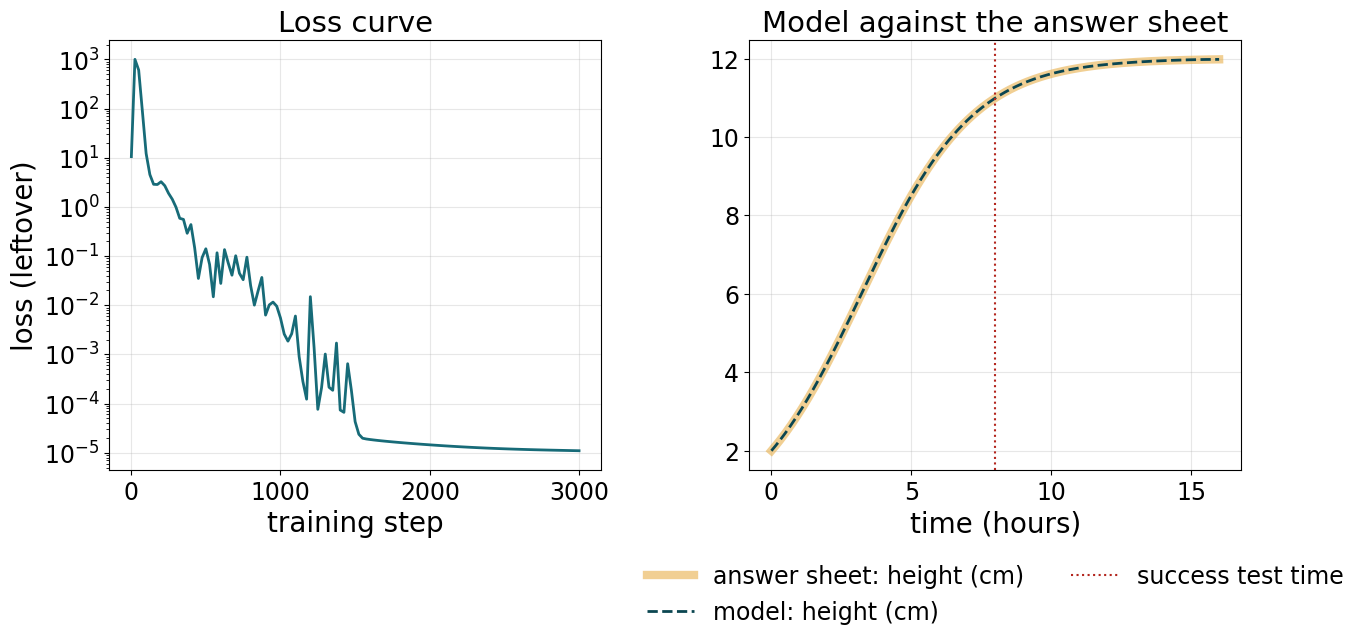

Biggest error against the answer sheet: 0.0049
Success test: at 8 hours, the model says 10.99 and the answer sheet says 10.99.
  Difference 0.000683, allowed 0.1: PASSED
Training time: 4 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as class_law_model.png.


In [ ]:
# The model that learns from the law (no examples), as in Week 8.
law_model = learn_law(rate, H0, t_end)
t = onp.linspace(0, t_end, 400)
law_report = report(law_model, t, exact(t), ["height (cm)"], "hours", check_time, check_tolerance, picture="class_law_model.png")

### The race
An ordinary model, **the same size, trained the same way**, learns from **examples** instead: 4, 8, 16, 32 and 64 points taken from the answer sheet, each with a little noise (2% of the range), like real measurements. Which is more accurate? How many examples does the ordinary model need to catch up? And how fast is each, per answer, compared with the standard solver?

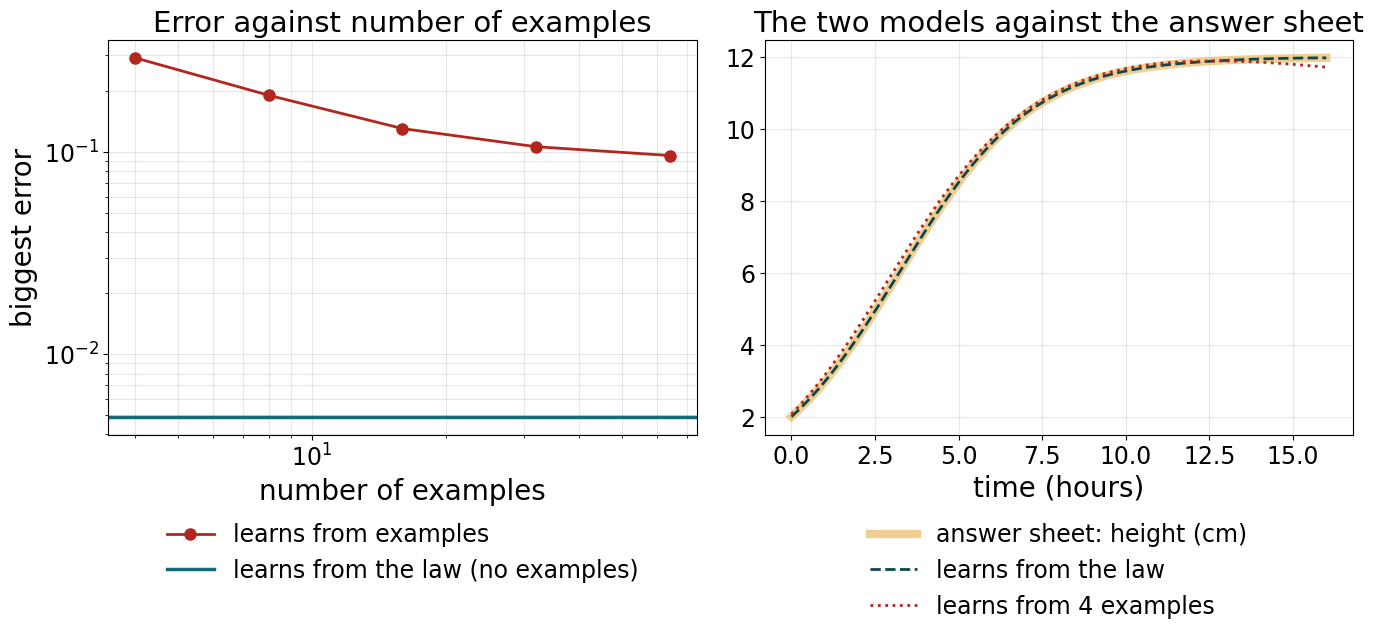

Model                               Examples   Biggest error  Size (numbers)
Learns from the law                        0          0.0049            1153
Learns from examples                       4           0.292            1153
Learns from examples                       8          0.1905            1153
Learns from examples                      16          0.1304            1153
Learns from examples                      32           0.106            1153
Learns from examples                      64         0.09595            1153

Time per answer: law model 6.7 µs, example model 4.1 µs, standard solver 6.3 µs
Finding: even with 64 examples, the example-learner was less accurate than the law-learner (error 0.0959 against 0.0049).
Saved as class_comparison.png.


In [ ]:
# The race: your law-learner against example-learners with 4 to 64 examples.
class_race = compare(law_model, rate, H0, t_end, t, exact(t), ["height (cm)"], "hours", picture="class_comparison.png")

### Outside the range
Now the examples are only measured during the **first 60%** of the time. The law-learner does not need examples at all. Which model still works where nothing was measured?

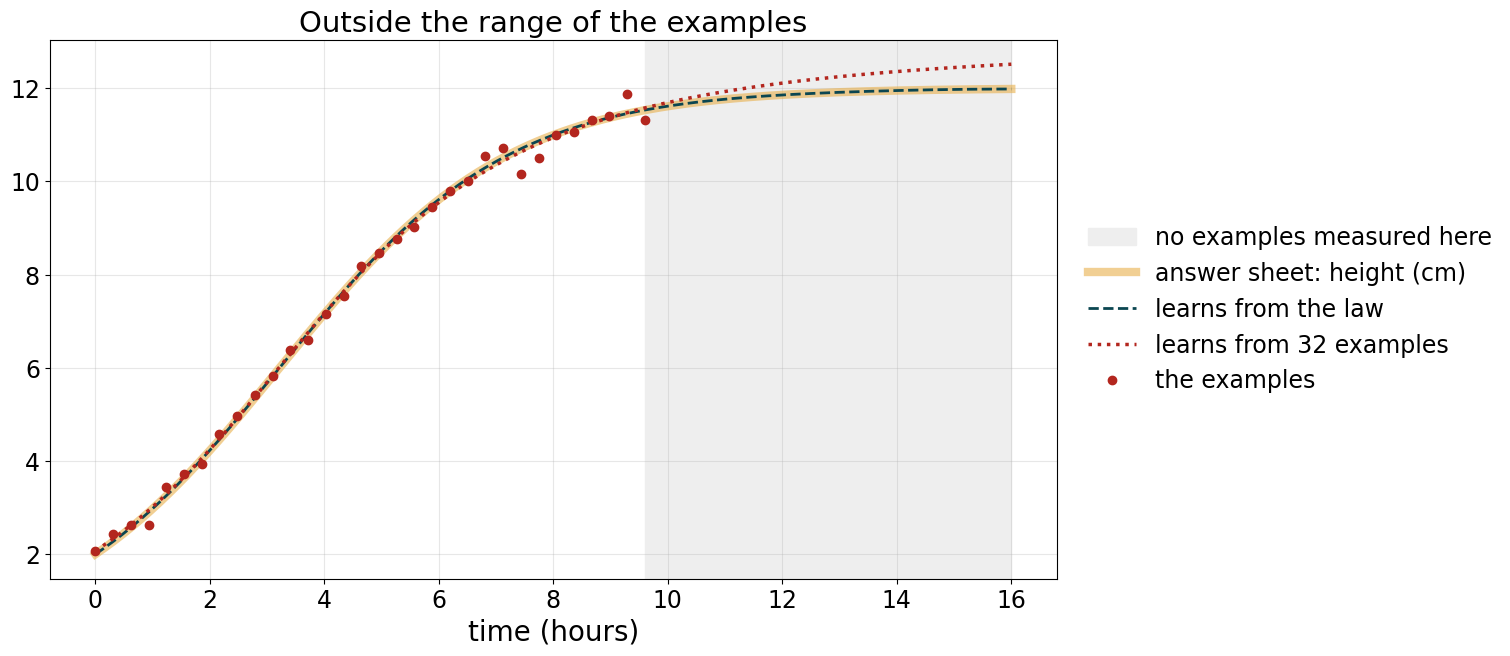

After 9.6 hours (no examples there): law-learner error 0.002869, example-learner error 0.5306.


In [ ]:
class_outside = outside_range(law_model, t, exact(t), t_end, ["height (cm)"], "hours", picture="class_outside_range.png")

### Shrink it
This week's topic, on your own model: make it **smaller**, first with fewer numbers (a smaller width), then with fewer binary digits per number (quantization), **until it fails your success test**. Keep the last version that passed.

In [ ]:
class_small = shrink(rate, H0, t_end, t, exact(t), "hours", check_time, check_tolerance)

 Width  Numbers  Bits each  Size (bytes)  At check time   Success test
    32     1153         32          4612          10.99   PASSED
    16      321         32          1284          10.99   PASSED
     8       97         32           388             11   PASSED
     4       33         32           132          10.99   PASSED
     2       13         32            52             11   PASSED
     2       13         16            26             11   PASSED
     2       13          8            13          10.99   PASSED
     2       13          4             6          11.42   not yet

Smallest model that passes: width 2, 13 numbers at 8 bits each = 13 bytes.


### Your finding, in one sentence with a number
For the class example: *"With no examples at all, the model that learns the law was about 20 times more accurate than one trained on 64 noisy measurements, kept working where no measurements existed, and still passed its success test at 13 bytes."* Write yours the same way: one sentence, with a number.

## Part 2 · ✏️ YOUR COMPARISON, if one thing changes over time
Copy in your Week 8 YOUR TURN cell (all of it, including your success test). Then run the next cell: it trains your law-learner, races it, tests outside the range, and shrinks it. About a minute.

In [ ]:
## This is my code from lab-8 ## Part 2
# YOUR FIRST MODEL
# Project: Predicting Coffee Cooling
# Scientific law: Newton's Law of Cooling

name = "Coffee Temperature (°C)"
time_unit = "minutes"

# ------------------------------------------
# Experimental parameters
# ------------------------------------------

start = 85.0
# Unit: °C
# Source: Initial coffee temperature measurement

b = 22.0
# Unit: °C
# Source: Ambient room temperature measurement

temp_after_10 = 60.0
# Unit: °C
# Source: Coffee temperature after 10 minutes

measurement_time = 10.0
# Unit: minutes

# Check that measurements are physically appropriate
assert start > temp_after_10 > b

# Calculate cooling constant
a = float(
    onp.log(
        (start - b) /
        (temp_after_10 - b)
    ) / measurement_time
)

# Unit: min^-1
# Source: Calculated from experimental measurements

t_end = 60.0
# Unit: minutes
# Source: Selected simulation duration

# ------------------------------------------
# Scientific law
# ------------------------------------------

def my_rate(t, y):
    return -a * (y - b)

# ------------------------------------------
# Exact analytical solution
# ------------------------------------------

HAS_EXACT = True

def my_exact(t):
    return b + (start - b) * onp.exp(-a * t)

# ------------------------------------------
# Success test
# ------------------------------------------

# Represents a 30-minute office meeting
check_time = 30.0

# Maximum permitted numerical error in °C
check_tolerance = 0.5

print("Your law is loaded.")
print(f"Initial temperature: {start} °C")
print(f"Room temperature: {b} °C")
print(f"Cooling constant: {a:.6f} min^-1")
print("Now run the next cell to train your model.")


Your law is loaded.
Initial temperature: 85.0 °C
Room temperature: 22.0 °C
Cooling constant: 0.050555 min^-1
Now run the next cell to train your model.


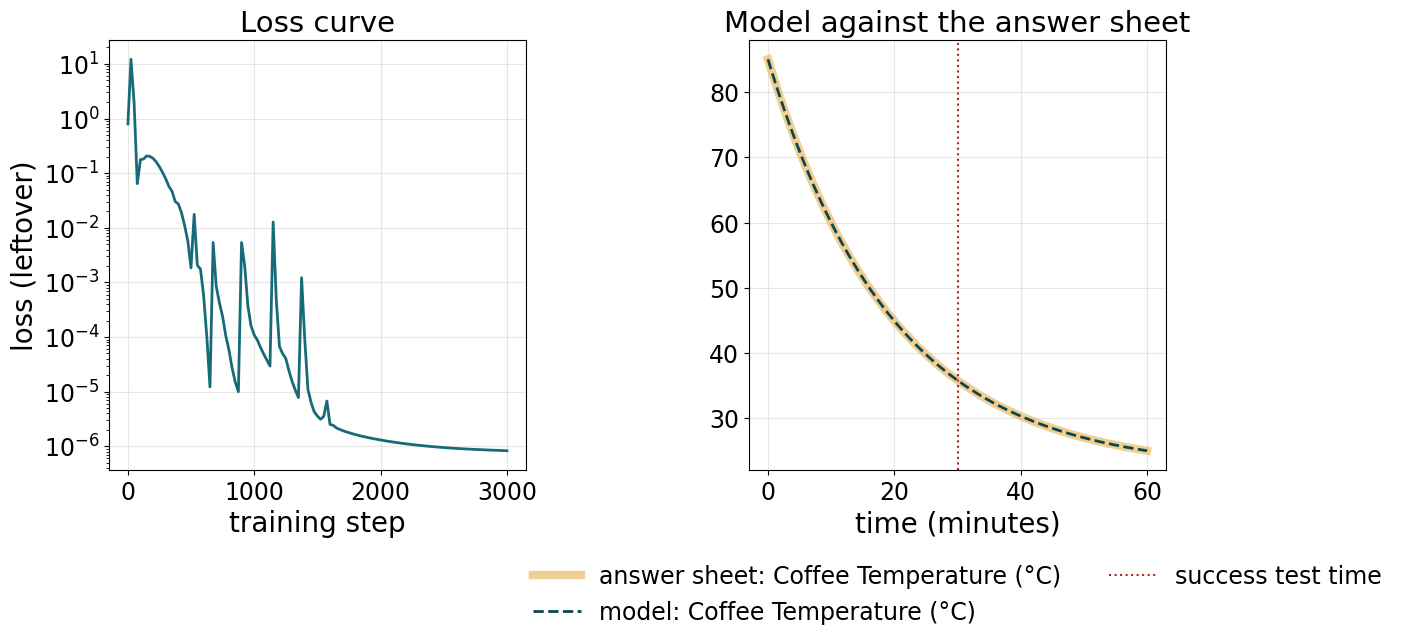

Biggest error against the answer sheet: 0.03451
Success test: at 30 minutes, the model says 35.82 and the answer sheet says 35.83.
  Difference 0.00894, allowed 0.5: PASSED
Training time: 3 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as my_law_model.png.


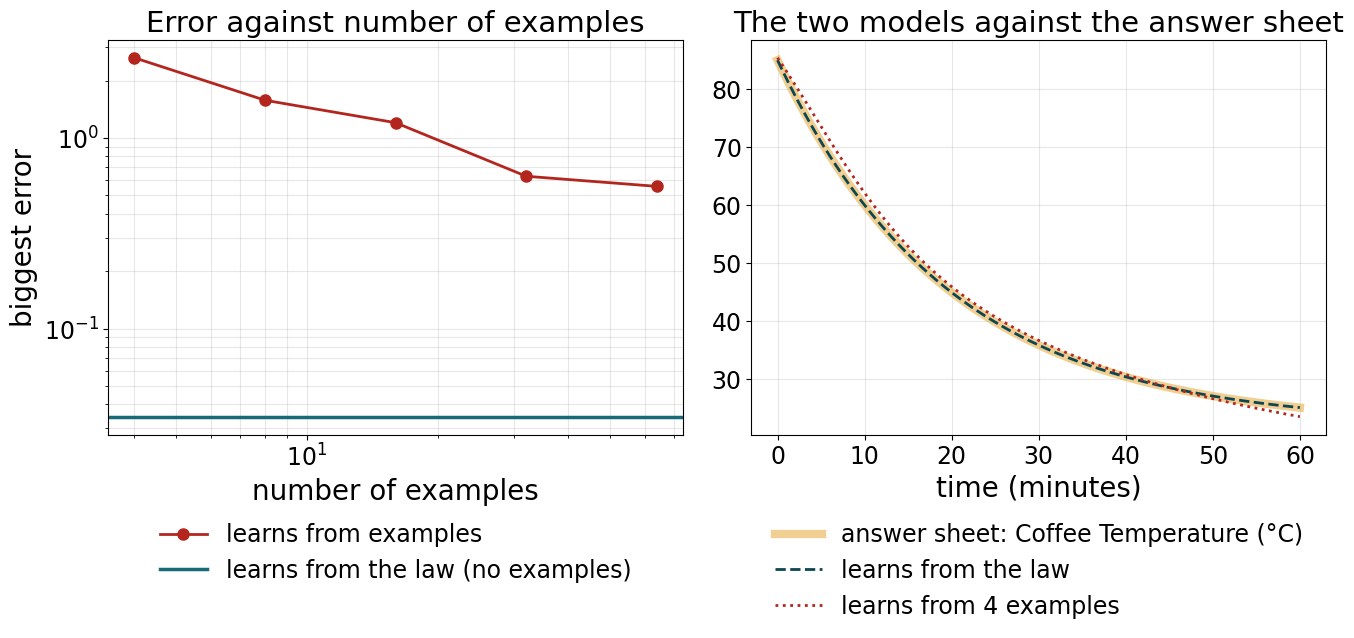

Model                               Examples   Biggest error  Size (numbers)
Learns from the law                        0         0.03451            1153
Learns from examples                       4           2.632            1153
Learns from examples                       8           1.576            1153
Learns from examples                      16           1.202            1153
Learns from examples                      32          0.6294            1153
Learns from examples                      64          0.5571            1153

Time per answer: law model 7.2 µs, example model 4.2 µs, standard solver 4.7 µs
Finding: even with 64 examples, the example-learner was less accurate than the law-learner (error 0.557 against 0.0345).
Saved as my_comparison.png.


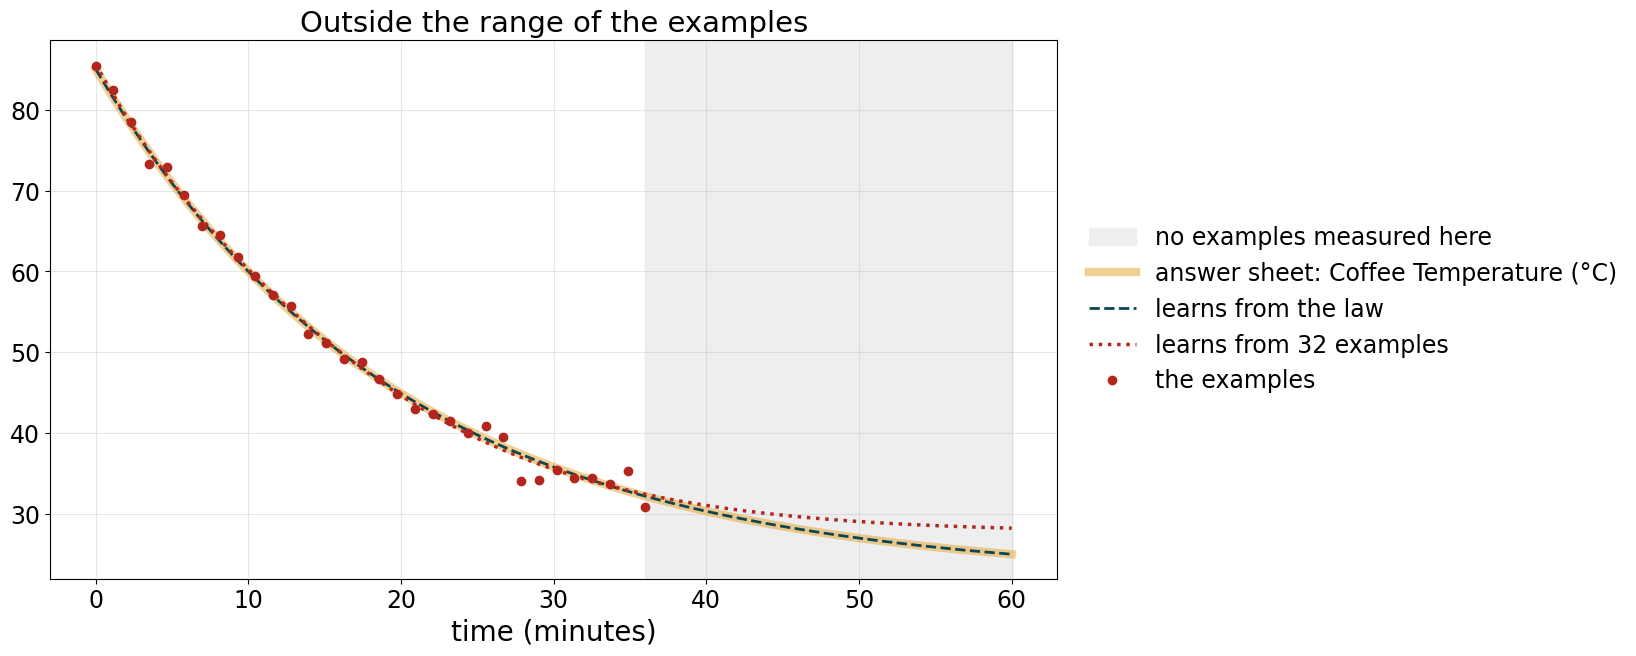

After 36 minutes (no examples there): law-learner error 0.005521, example-learner error 3.225.
 Width  Numbers  Bits each  Size (bytes)  At check time   Success test
    32     1153         32          4612          35.82   PASSED
    16      321         32          1284          35.81   PASSED
     8       97         32           388          35.84   PASSED
     4       33         32           132          35.83   PASSED
     2       13         32            52          35.88   PASSED
     2       13         16            26          35.88   PASSED
     2       13          8            13          35.72   PASSED
     2       13          4             6          26.55   not yet

Smallest model that passes: width 2, 13 numbers at 8 bits each = 13 bytes.

For the form: your table (above), my_comparison.png, my_outside_range.png, and your finding in one sentence with a number.


In [ ]:
# Your comparison. Just run this cell.
t = onp.linspace(0, t_end, 400)
sheet = my_exact(t) if HAS_EXACT else solve_ivp(lambda tt, y: [float(my_rate(tt, y[0]))], (0, t_end), [start], t_eval=t, rtol=1e-8, atol=1e-10).y[0]
my_law = learn_law(my_rate, start, t_end)
my_report = report(my_law, t, sheet, [name], time_unit, check_time, check_tolerance, picture="my_law_model.png")
my_race = compare(my_law, my_rate, start, t_end, t, sheet, [name], time_unit)
my_outside = outside_range(my_law, t, sheet, t_end, [name], time_unit)
my_small = shrink(my_rate, start, t_end, t, sheet, time_unit, check_time, check_tolerance)
print("\nFor the form: your table (above), my_comparison.png, my_outside_range.png, and your finding in one sentence with a number.")

## Part 3 · ✏️ YOUR COMPARISON, if two or three things change each other
Copy in your Week 8 Part 3 YOUR TURN cell, then run the next cell.

In [ ]:
# ✏️ YOUR TURN (only if your law has two or three things that change each other).
names  = ["tank A (litres)", "tank B (litres)"]   # <-- one name per thing
k1 = 0.3                     # <-- a number    (unit, source)
k2 = 0.1                     # <-- a number    (unit, source)
starts = [10.0, 0.0]         # <-- starting values, one per thing
t_end3 = 30.0                # <-- how long to look
time_unit3 = "minutes"       # <-- your unit of time

def my_rates(t, y):
    A, B = y                 # <-- one short name per thing, in the same order as names
    dA = -k1 * A             # <-- how fast the first thing changes
    dB = k1 * A - k2 * B     # <-- how fast the second thing changes
    return [dA, dB]          # <-- list them all, in the same order

which = 1                    # <-- which thing your success test checks (0 = first, 1 = second, ...)
check_time3 = 15.0           # <-- your success test: the time to check ...
check_tolerance3 = 0.2       # <-- ... and how close it must be
print("Your law is loaded. Now run the next cell.")

Your law is loaded. Now run the next cell.


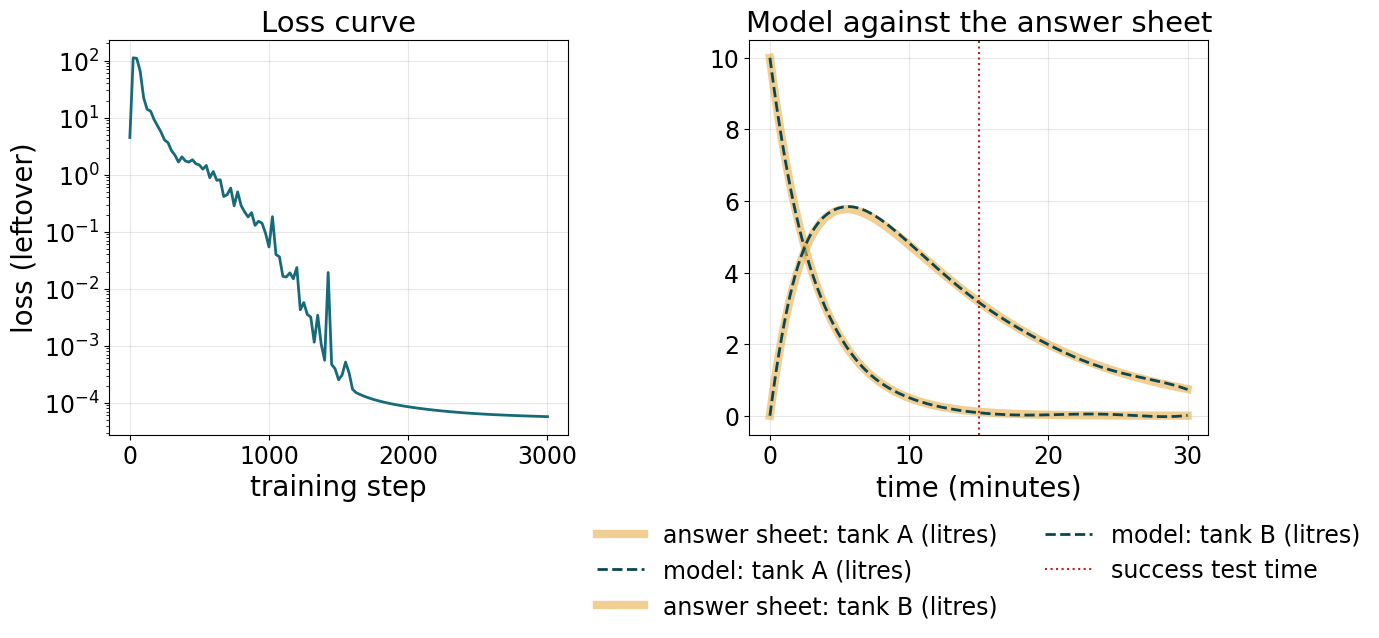

Biggest error against the answer sheet: 0.1201
Success test: at 15 minutes, the model says 3.171 and the answer sheet says 3.18.
  Difference 0.00945, allowed 0.2: PASSED
Training time: 5 seconds. Model size: 1186 numbers. Checking points: 200.
Saved as my_law_model.png.


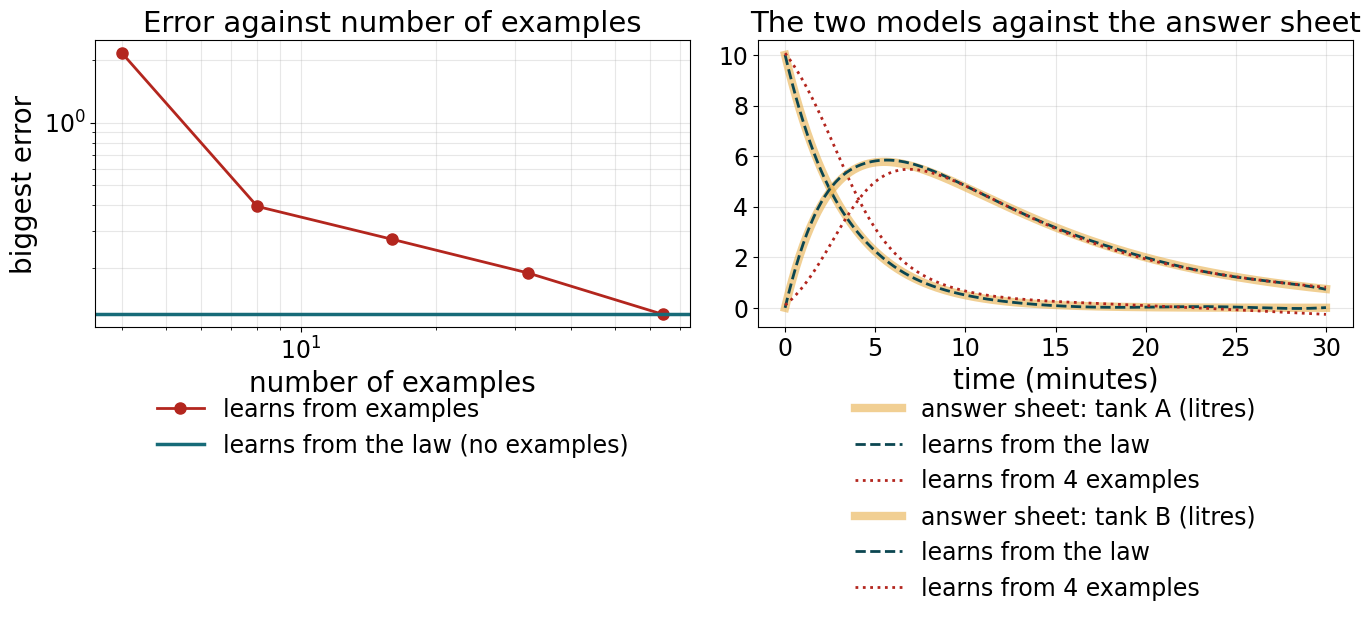

Model                               Examples   Biggest error  Size (numbers)
Learns from the law                        0          0.1201            1186
Learns from examples                       4           2.165            1186
Learns from examples                       8          0.3948            1186
Learns from examples                      16          0.2738            1186
Learns from examples                      32          0.1887            1186
Learns from examples                      64          0.1191            1186

Time per answer: law model 8.4 µs, example model 5.7 µs, standard solver 20.5 µs
Finding: the example-learner needed 64 examples to be as accurate as the law-learner.
Saved as my_comparison.png.


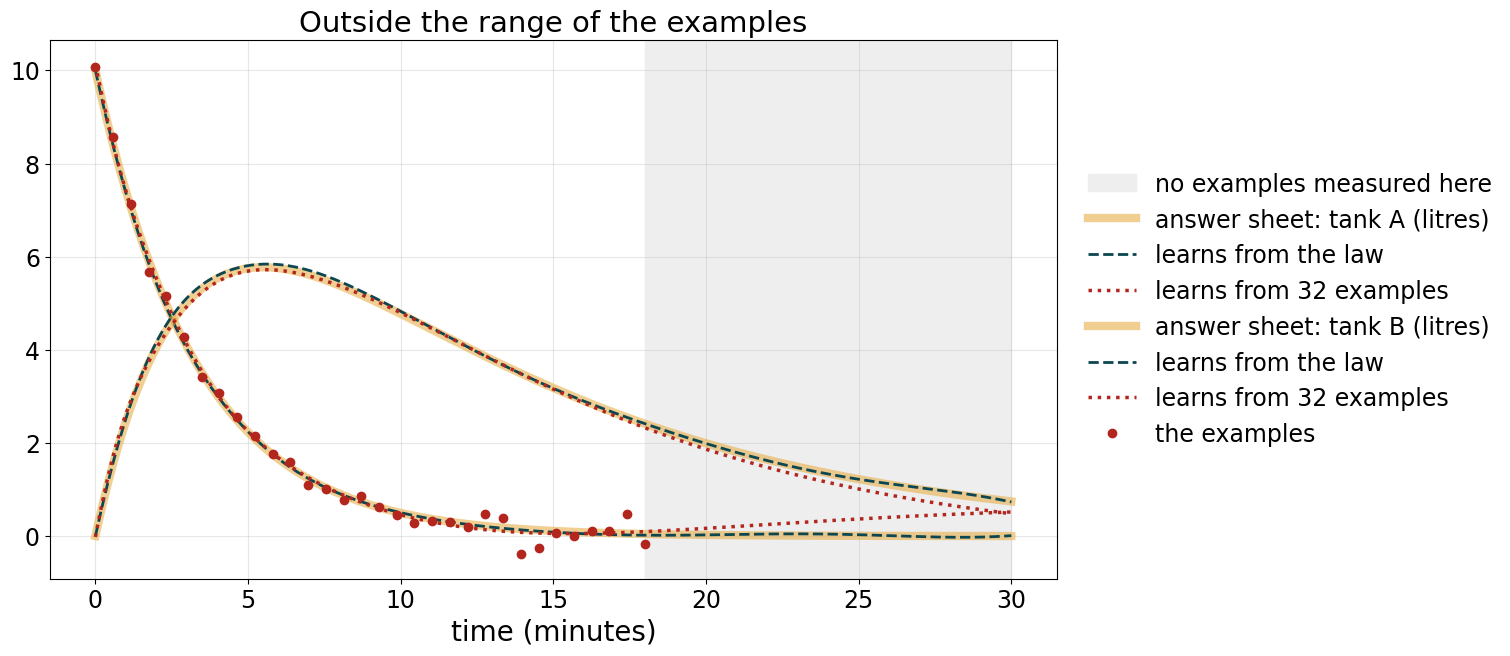

After 18 minutes (no examples there): law-learner error 0.04543, example-learner error 0.5169.
 Width  Numbers  Bits each  Size (bytes)  At check time   Success test
    32     1186         32          4744          3.171   PASSED
    16      338         32          1352          3.175   PASSED
     8      106         32           424            3.1   PASSED
     4       38         32           152          3.286   PASSED
     2       16         32            64          2.705   not yet
     4       38         16            76          3.286   PASSED
     4       38          8            38          3.001   PASSED
     4       38          4            19         -2.521   not yet

Smallest model that passes: width 4, 38 numbers at 8 bits each = 38 bytes.


In [ ]:
# Your comparison. Just run this cell.
t3 = onp.linspace(0, t_end3, 300)
sheet3 = solve_ivp(lambda tt, y: onp.asarray([float(v) for v in my_rates(tt, y)]), (0, t_end3), starts, t_eval=t3, rtol=1e-8, atol=1e-10).y
my_law3 = learn_law(my_rates, starts, t_end3)
my_report3 = report(my_law3, t3, sheet3, names, time_unit3, check_time3, check_tolerance3, which=which, picture="my_law_model.png")
my_race3 = compare(my_law3, my_rates, starts, t_end3, t3, sheet3, names, time_unit3)
my_outside3 = outside_range(my_law3, t3, sheet3, t_end3, names, time_unit3)
my_small3 = shrink(my_rates, starts, t_end3, t3, sheet3, time_unit3, check_time3, check_tolerance3, which=which)

## Part 4 · ✏️ YOUR COMPARISON, if it changes over time and along a line
Copy in your Week 8 Part 4 YOUR TURN cell, then run the next cell. It trains several models, so it takes about four minutes.

In [ ]:
# ✏️ YOUR TURN (only if your law changes over time and along a line).
D = 1.0                      # <-- how fast it spreads   (km² per year, source: ...)
g = 1.0                      # <-- how fast it grows     (per year, source: ...)
L = 40.0                     # <-- length of the line    (km)
t_end4 = 8.0                 # <-- how long to look      (years)
name4 = "share of the coastline settled"   # <-- what changes

def my_line_law(u, u_x, u_xx):              # how fast it changes at a point on the line
    return D * u_xx + g * u * (1 - u)       # <-- YOUR LAW (Week 7's "bend" is u_xx here)

def u0(x):                                  # <-- the starting values along the line
    return np.exp(-x**2 / 4)

times = [0, 2, 4, 6, 8]      # <-- moments to draw (the last one is t_end4)
check_place, check_time4, check_tolerance4 = 10.0, 8.0, 0.05   # <-- your success test
print("Your law is loaded. Now run the next cell (about a minute).")

Your law is loaded. Now run the next cell (about a minute).


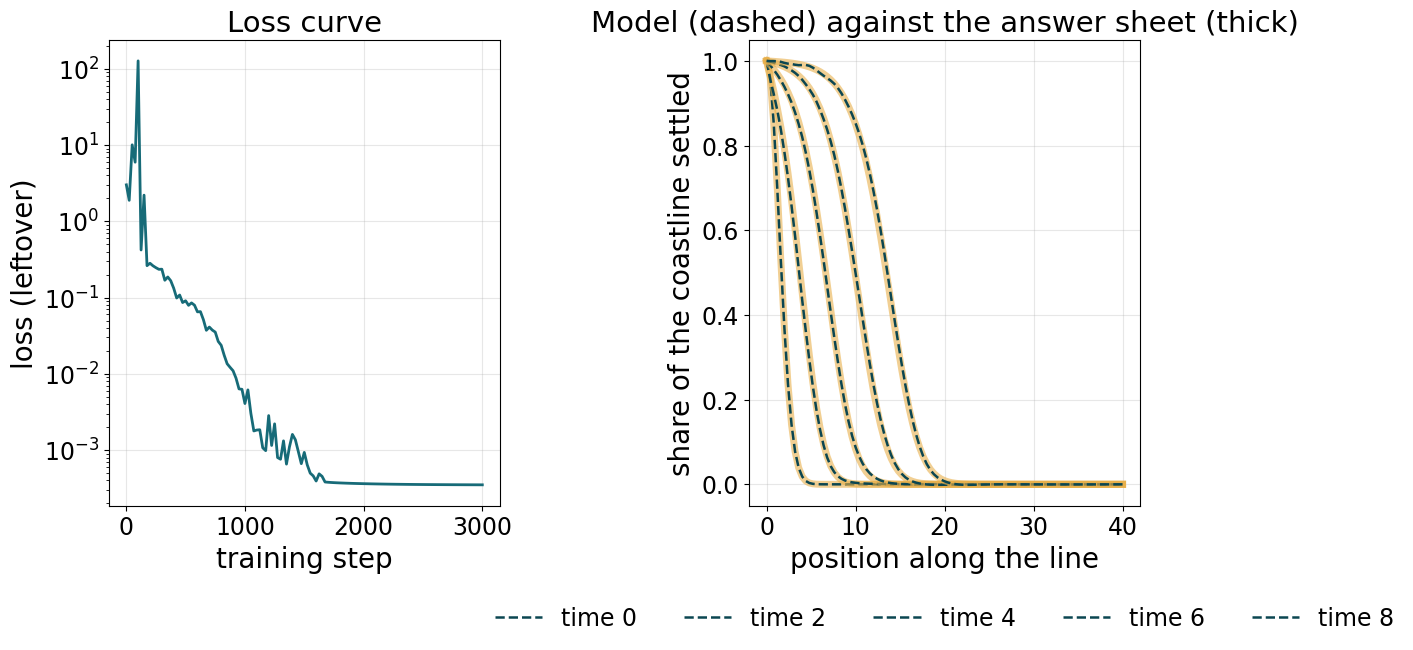

Biggest error against the answer sheet: 0.0169
Success test: at place 10, time 8, the model says 0.8527 and the answer sheet says 0.8501.
  Difference 0.00254, allowed 0.05: PASSED
Training time: 84 seconds. Model size: 2241 numbers. Checking points: 3000.


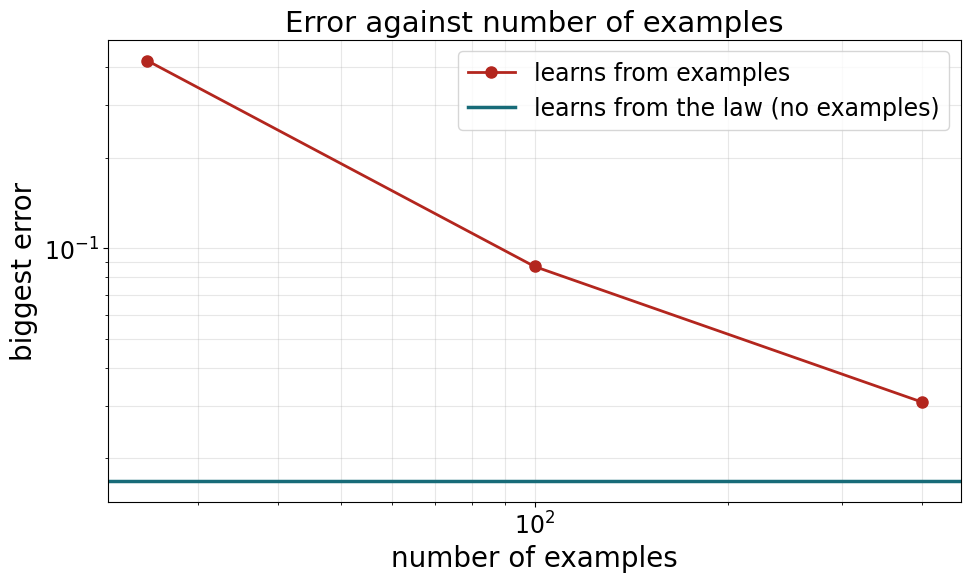

Model                       Examples   Biggest error  Size (numbers)
Learns from the law                0          0.0169            2241
Learns from examples              25          0.4206            2241
Learns from examples             100         0.08694            2241
Learns from examples             400         0.03079            2241
Finding: even with 400 examples, the example-learner was less accurate (error 0.0308 against 0.0169).
 Width  Numbers  At check point   Success test
    16      609          0.8147   PASSED
     8      177          0.7691   not yet

Smallest model that passes: width 16, 609 numbers (2436 bytes).


In [ ]:
# Your comparison. Just run this cell (about four minutes).
x4, sheet4 = line_answer_sheet(my_line_law, lambda xx: onp.asarray(u0(xx)), L, t_end4, times)
my_law4 = learn_line_law(my_line_law, u0, L, t_end4)
my_report4 = line_report(my_law4, x4, sheet4, times, name4, check_place, check_time4, check_tolerance4, picture="my_law_model.png")
my_race4 = line_compare(my_law4, x4, sheet4, times, L, t_end4, name4)
my_small4 = line_shrink(my_line_law, u0, L, t_end4, x4, sheet4, times, check_place, check_time4, check_tolerance4)

## Done · What to hand in (the Week 9 form)
- **Part A:** the size and eval rate of the normal and the shrunk model, and which you would put on a phone.
- **Your table** (accuracy and size of each model, and the time per answer).
- **Your chart** `my_comparison.png` (and `my_outside_range.png`, if you have it).
- **Your finding, in one sentence with a number.**
- **The smallest version of your model that still passes your success test.**

**When it goes wrong:** the same as last week. If your law-learner fails its success test, try the four fixes before racing it. If an example-learner's error does not fall as the examples grow, that is a finding, not a mistake: noise in the examples limits it.